In [37]:
import numpy as np
import pandas as pd

In [38]:
# load Transactions.csv file within the Data directory into a pandas DataFrame
df = pd.read_csv('../Data/Transactions.csv')
df.head(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [39]:
# total number of transactions
total_transactions = len(df)
print(f'Total number of transactions: {total_transactions}')

# Total number of transactions where amount is greater than 200000
high_value_transactions = df[df['amount'] > 200000]
print(f'Total number of transactions with amount greater than 200000: {len(high_value_transactions)}')

# Total number of transactions where isFlaggedFraud is 1
flagged_fraud_transactions = df[df['isFlaggedFraud'] == 1]
print(f'Total number of transactions flagged as fraud: {len(flagged_fraud_transactions)}')

# Total number of transactions where amount is greater than 200000 and isFlaggedFraud is 1
fraudulent_transactions = df[(df['amount'] > 200000) & (df['isFlaggedFraud'] == 1)]
print(f'Total number of fraudulent transactions: {len(fraudulent_transactions)}')

Total number of transactions: 6362620
Total number of transactions with amount greater than 200000: 1673570
Total number of transactions flagged as fraud: 16
Total number of fraudulent transactions: 16


In [40]:
# Total number of transactions where isFraud is 1
fraud_transactions = df[df['isFraud'] == 1]
print(f'Total number of transactions that are fraudulent: {len(fraud_transactions)}')

Total number of transactions that are fraudulent: 8213


# Data Validation

In [41]:
# Create a new column with value newbalanceOrig + amount − oldbalanceOrg
df['errorOrig'] = df['oldbalanceOrg'] - df['amount'] - df['newbalanceOrig']

df['errorOrig'].head(15)


0     0.000000e+00
1     0.000000e+00
2     0.000000e+00
3     0.000000e+00
4     0.000000e+00
5     0.000000e+00
6     0.000000e+00
7     0.000000e+00
8    -1.353360e+03
9    -7.275958e-12
10   -5.179940e+03
11    0.000000e+00
12    0.000000e+00
13   -1.506760e+03
14    0.000000e+00
Name: errorOrig, dtype: float64

In [42]:
# Total number of transactions where nameOrig is equal to nameDest
same_name_transactions = df[df['nameOrig'] == df['nameDest']]
print(f'Total number of transactions where nameOrig is equal to nameDest: {len(same_name_transactions)}')

Total number of transactions where nameOrig is equal to nameDest: 0


In [43]:
# Number of transactions where the nameOrigin does not start with 'C'
non_c_name_transactions = df[~df['nameOrig'].str.startswith('C')]
print(f'Number of transactions where the nameOrigin does not start with \'C\': {len(non_c_name_transactions)}')

Number of transactions where the nameOrigin does not start with 'C': 0


In [44]:
# What percentage of transactions where isFraud==1, have nameDest starting with 'C'?
fraud_transactions_with_c_dest = df[(df['isFraud'] == 1) & (df['nameDest'].str.startswith('C'))]
percentage_fraud_with_c_dest = (len(fraud_transactions_with_c_dest) / len(fraud_transactions)) * 100
print(f'Percentage of fraudulent transactions where nameDest starts with \'C\': {percentage_fraud_with_c_dest:.2f}%')

Percentage of fraudulent transactions where nameDest starts with 'C': 100.00%


In [45]:
# Top 10 rows of the dataframe where isFraud == 1
df[df['isFraud'] == 1].head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,errorOrig
2,1,TRANSFER,181.00,C1305486145,181.00,0.0,C553264065,0.0,0.00,1,0,0.00
3,1,CASH_OUT,181.00,C840083671,181.00,0.0,C38997010,21182.0,0.00,1,0,0.00
251,1,TRANSFER,2806.00,C1420196421,2806.00,0.0,C972765878,0.0,0.00,1,0,0.00
252,1,CASH_OUT,2806.00,C2101527076,2806.00,0.0,C1007251739,26202.0,0.00,1,0,0.00
680,1,TRANSFER,20128.00,C137533655,20128.00,0.0,C1848415041,0.0,0.00,1,0,0.00
681,1,CASH_OUT,20128.00,C1118430673,20128.00,0.0,C339924917,6268.0,12145.85,1,0,0.00
724,1,CASH_OUT,416001.33,C749981943,0.00,0.0,C667346055,102.0,9291619.62,1,0,-416001.33
969,1,TRANSFER,1277212.77,C1334405552,1277212.77,0.0,C431687661,0.0,0.00,1,0,0.00
970,1,CASH_OUT,1277212.77,C467632528,1277212.77,0.0,C716083600,0.0,2444985.19,1,0,0.00
1115,1,TRANSFER,35063.63,C1364127192,35063.63,0.0,C1136419747,0.0,0.00,1,0,0.00


In [46]:
# print total number of transactions where amount is greater than oldbalanceOrg
high_amount_transactions = df[df['amount'] > df['oldbalanceOrg']+1]
print(f'Total number of transactions where amount is greater than oldbalanceOrg: {len(high_amount_transactions)}')

# print the top 10 rows of the dataframe where amount is greater than oldbalanceOrg
df[df['amount'] > df['oldbalanceOrg']+1].head(10)

Total number of transactions where amount is greater than oldbalanceOrg: 4079018


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,errorOrig
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.0,M1176932104,0.0,0.00,0,0,-1353.36
10,1,DEBIT,9644.94,C1900366749,4465.00,0.0,C997608398,10845.0,157982.12,0,0,-5179.94
13,1,PAYMENT,11633.76,C1716932897,10127.00,0.0,M801569151,0.0,0.00,0,0,-1506.76
15,1,CASH_OUT,229133.94,C905080434,15325.00,0.0,C476402209,5083.0,51513.44,0,0,-213808.94
16,1,PAYMENT,1563.82,C761750706,450.00,0.0,M1731217984,0.0,0.00,0,0,-1113.82
19,1,TRANSFER,215310.30,C1670993182,705.00,0.0,C1100439041,22425.0,0.00,0,0,-214605.30
24,1,TRANSFER,311685.89,C1984094095,10835.00,0.0,C932583850,6267.0,2719172.89,0,0,-300850.89
25,1,PAYMENT,6061.13,C1043358826,443.00,0.0,M1558079303,0.0,0.00,0,0,-5618.13
28,1,PAYMENT,8901.99,C1632497828,2958.91,0.0,M33419717,0.0,0.00,0,0,-5943.08
29,1,PAYMENT,9920.52,C764826684,0.00,0.0,M1940055334,0.0,0.00,0,0,-9920.52


In [47]:
# Create a new df from the original df where amount > oldbalanceOrg
high_amount_transactions = df[df['amount'] > df['oldbalanceOrg']]

#Create a bar chart showing the number of transacions in 'high_amount_transactions' where isFraud == 1 and isFraud == 0


fraud_count = high_amount_transactions[high_amount_transactions['isFraud'] == 1].shape[0]
non_fraud_count = high_amount_transactions[high_amount_transactions['isFraud'] == 0].shape[0]

fraud_count



29

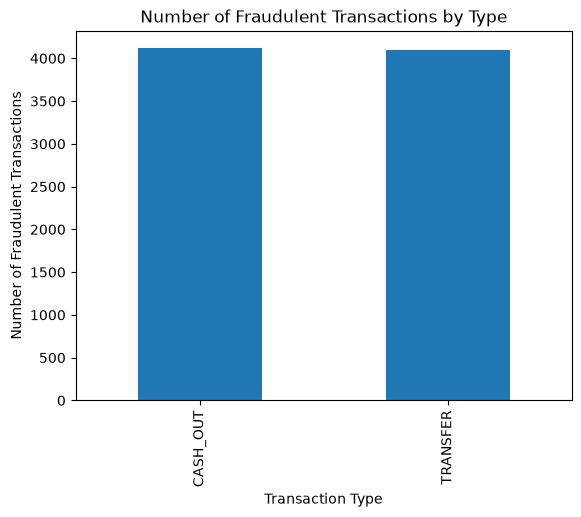

In [48]:
# Bar chart showing the number of transactions where isFraud==1 for each category in the type column
import matplotlib.pyplot as plt
fraud_transactions_by_type = df[df['isFraud'] == 1].groupby('type').size()
fraud_transactions_by_type.plot(kind='bar')
plt.title('Number of Fraudulent Transactions by Type')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Fraudulent Transactions')
plt.show()

In [49]:
# total transactions with isFraud==1 and type is not CASH_OUT and not TRANSFER
fraud_transactions_not_cash_out_transfer = df[(df['isFraud'] == 1) & (df['type'] != 'CASH_OUT') & (df['type'] != 'TRANSFER')]
print(f'Total number of fraudulent transactions that are not CASH_OUT or TRANSFER: {len(fraud_transactions_not_cash_out_transfer)}')

Total number of fraudulent transactions that are not CASH_OUT or TRANSFER: 0


In [50]:
# Create a new df with transaction where type is CASH_OUT or TRANSFER
df_cash_out_transfer = df[(df['type'] == 'CASH_OUT') | (df['type'] == 'TRANSFER')]
df_cash_out_transfer.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,errorOrig
2,1,TRANSFER,181.00,C1305486145,181.00,0.0,C553264065,0.0,0.00,1,0,0.000000e+00
3,1,CASH_OUT,181.00,C840083671,181.00,0.0,C38997010,21182.0,0.00,1,0,0.000000e+00
15,1,CASH_OUT,229133.94,C905080434,15325.00,0.0,C476402209,5083.0,51513.44,0,0,-2.138089e+05
19,1,TRANSFER,215310.30,C1670993182,705.00,0.0,C1100439041,22425.0,0.00,0,0,-2.146053e+05
24,1,TRANSFER,311685.89,C1984094095,10835.00,0.0,C932583850,6267.0,2719172.89,0,0,-3.008509e+05
42,1,CASH_OUT,110414.71,C768216420,26845.41,0.0,C1509514333,288800.0,2415.16,0,0,-8.356930e+04
47,1,CASH_OUT,56953.90,C1570470538,1942.02,0.0,C824009085,70253.0,64106.18,0,0,-5.501188e+04
48,1,CASH_OUT,5346.89,C512549200,0.00,0.0,C248609774,652637.0,6453430.91,0,0,-5.346890e+03
51,1,CASH_OUT,23261.30,C2072313080,20411.53,0.0,C2001112025,25742.0,0.00,0,0,-2.849770e+03
58,1,TRANSFER,62610.80,C1976401987,79114.00,16503.2,C1937962514,517.0,8383.29,0,0,-3.637979e-12


In [51]:
# Percentage of transactions in df_cash_out_transfer where isFraud==1
fraud_transactions_in_cash_out_transfer = df_cash_out_transfer[df_cash_out_transfer['isFraud'] == 1]
percentage_fraud_in_cash_out_transfer = (len(fraud_transactions_in_cash_out_transfer) / len(df_cash_out_transfer)) * 100
print(f'Percentage of   transactions in CASH_OUT or TRANSFER that are fraudulent: {percentage_fraud_in_cash_out_transfer:.2f}%')

Percentage of   transactions in CASH_OUT or TRANSFER that are fraudulent: 0.30%


In [52]:
# correlation matrix between all the numeric columns in the dataframe
correlation_matrix = df.corr(numeric_only=True)

# display the correlation matrix
correlation_matrix

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,errorOrig
step,1.000000,0.022373,-0.010058,-0.010299,0.027665,0.025888,0.031578,0.003277,-0.020516
amount,0.022373,1.000000,-0.002762,-0.007861,0.294137,0.459304,0.076688,0.012295,-0.970660
oldbalanceOrg,-0.010058,-0.002762,1.000000,0.998803,0.066243,0.042029,0.010154,0.003835,-0.050502
newbalanceOrig,-0.010299,-0.007861,0.998803,1.000000,0.067812,0.041837,-0.008148,0.003776,-0.056897
oldbalanceDest,0.027665,0.294137,0.066243,0.067812,1.000000,0.976569,-0.005885,-0.000513,-0.304256
newbalanceDest,0.025888,0.459304,0.042029,0.041837,0.976569,1.000000,0.000535,-0.000529,-0.458750
isFraud,0.031578,0.076688,0.010154,-0.008148,-0.005885,0.000535,1.000000,0.044109,0.011283
isFlaggedFraud,0.003277,0.012295,0.003835,0.003776,-0.000513,-0.000529,0.044109,1.000000,-0.012183
errorOrig,-0.020516,-0.970660,-0.050502,-0.056897,-0.304256,-0.458750,0.011283,-0.012183,1.000000


In [53]:
# Create a new column "hour_of_day" that contains the hour of the day (0-23) when the transaction occurred. The "step" column contains the number of hours since the first transaction in the dataset, so we can use modulo 24 to get the hour of the day.
df['hour_of_day'] = df['step'] % 24

# Create a new column "day"
df['day'] = df['step'] // 24

df.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,errorOrig,hour_of_day,day
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0,0.000000e+00,1,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0,0.000000e+00,1,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0,0.000000e+00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0,0.000000e+00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0,0.000000e+00,1,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0,0.000000e+00,1,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0,0.000000e+00,1,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0,0.000000e+00,1,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0,-1.353360e+03,1,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0,-7.275958e-12,1,0


In [62]:
# unique values in the "hour_of_day" column
unique_hours = df['hour_of_day'].unique()
print(f'Unique hours of the day when transactions occurred: {unique_hours}')

# Unique values in the "day" column
unique_days = df['day'].unique()
print(f'Unique days when transactions occurred: {unique_days}')

# map 'day' column to the corresponding day of the week (0=Sunday, 1=Monday, ..., 6=Saturday)
day_map = {0: 'Friday', 1: 'Saturday', 2: 'Sunday', 3: 'Monday', 4: 'Tuesday', 5: 'Wednesday', 6: 'Thursday',
           7: 'Friday', 8: 'Saturday', 9: 'Sunday', 10: 'Monday', 11: 'Tuesday', 12: 'Wednesday', 13: 'Thursday',
           14: 'Friday', 15: 'Saturday', 16: 'Sunday', 17: 'Monday', 18: 'Tuesday', 19: 'Wednesday', 20: 'Thursday',
           21: 'Friday', 22: 'Saturday', 23: 'Sunday', 24: 'Monday', 25: 'Tuesday', 26: 'Wednesday',27: 'Thursday', 
           28: 'test', 29: 'test2', 30: 'test3'}

df['day_of_week'] = df['day'].map(day_map)

Unique hours of the day when transactions occurred: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23  0]
Unique days when transactions occurred: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30]


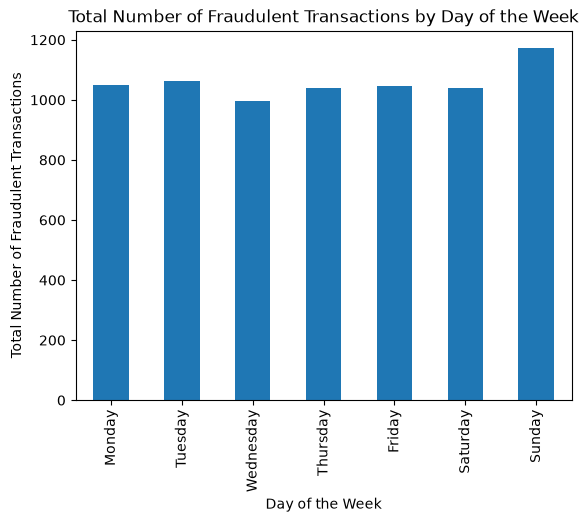

In [63]:
# Create a bar chart showing the total number of fraudulent transactions by 'day_of_week'.
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
fraud_transactions_by_day = df[df['isFraud'] == 1].groupby('day_of_week').size().reindex(day_order)
fraud_transactions_by_day.plot(kind='bar')
plt.title('Total Number of Fraudulent Transactions by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Total Number of Fraudulent Transactions')
plt.show()

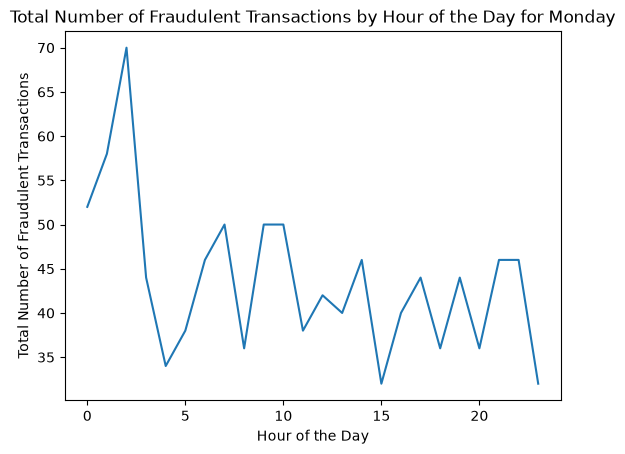

In [56]:
# filter df to only include 'Monday' as the day of the week
monday_transactions = df[df['day_of_week'] == 'Monday']

# Create a line chart to show the total number of fraudulent transactions by hour of the day for 'Monday' transactions
fraud_transactions_by_hour_monday = monday_transactions[monday_transactions['isFraud'] == 1].groupby('hour_of_day').size()
fraud_transactions_by_hour_monday.plot(kind='line')
plt.title('Total Number of Fraudulent Transactions by Hour of the Day for Monday')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Number of Fraudulent Transactions')
plt.show()

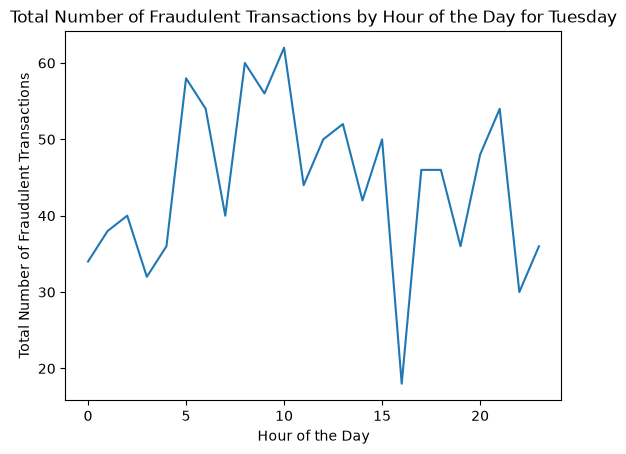

In [57]:
# filter df to only include 'Tuesday' as the day of the week
tuesday_transactions = df[df['day_of_week'] == 'Tuesday']

# Create a line chart to show the total number of fraudulent transactions by hour of the day for 'Tuesday' transactions
fraud_transactions_by_hour_tuesday = tuesday_transactions[tuesday_transactions['isFraud'] == 1].groupby('hour_of_day').size()
fraud_transactions_by_hour_tuesday.plot(kind='line')
plt.title('Total Number of Fraudulent Transactions by Hour of the Day for Tuesday')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Number of Fraudulent Transactions')
plt.show()

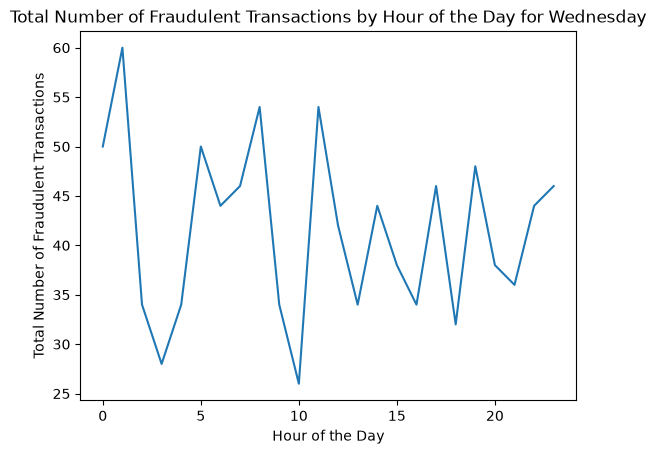

In [58]:
# filter df to only include 'Wednesday' as the day of the week
wednesday_transactions = df[df['day_of_week'] == 'Wednesday']

# Create a line chart to show the total number of fraudulent transactions by hour of the day for 'Wednesday' transactions
fraud_transactions_by_hour_wednesday = wednesday_transactions[wednesday_transactions['isFraud'] == 1].groupby('hour_of_day').size()
fraud_transactions_by_hour_wednesday.plot(kind='line')
plt.title('Total Number of Fraudulent Transactions by Hour of the Day for Wednesday')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Number of Fraudulent Transactions')
plt.show()

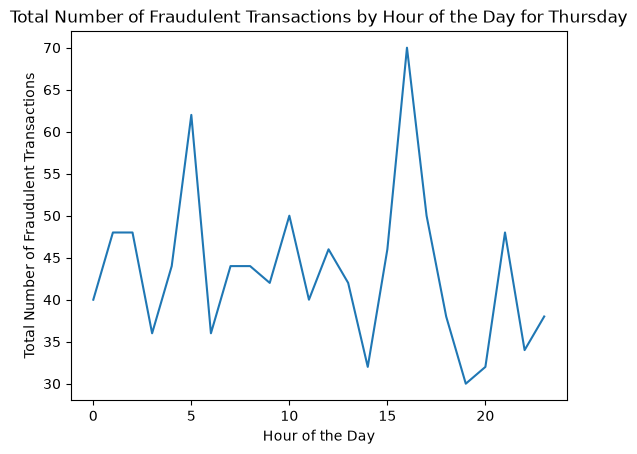

In [59]:
# filter df to only include 'Thursday' as the day of the week
thursday_transactions = df[df['day_of_week'] == 'Thursday']

# Create a line chart to show the total number of fraudulent transactions by hour of the day for 'Thursday' transactions
fraud_transactions_by_hour_thursday = thursday_transactions[thursday_transactions['isFraud'] == 1].groupby('hour_of_day').size()
fraud_transactions_by_hour_thursday.plot(kind='line')
plt.title('Total Number of Fraudulent Transactions by Hour of the Day for Thursday')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Number of Fraudulent Transactions')
plt.show()

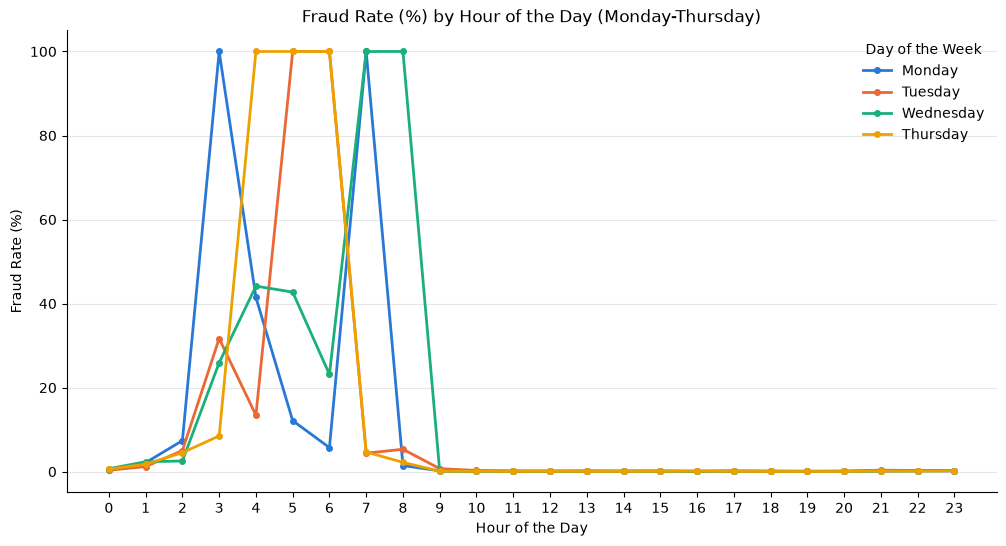

In [65]:
# Combine the Monday-Thursday line charts into a single chart showing the fraud rate (%) by hour of the day for each day
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday']
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']

# Fraud rate per (day_of_week, hour_of_day) = fraudulent transactions / all transactions * 100
fraud_rate_by_day_hour = (df[df['day_of_week'].isin(days)]
                          .groupby(['day_of_week', 'hour_of_day'])['isFraud'].mean()
                          .mul(100)
                          .unstack('day_of_week')
                          .reindex(index=range(24), columns=days))

fig, ax = plt.subplots(figsize=(12, 6))
for day, color in zip(days, colors):
    ax.plot(fraud_rate_by_day_hour.index, fraud_rate_by_day_hour[day], label=day, color=color, linewidth=2, marker='o', markersize=4)

ax.set_title('Fraud Rate (%) by Hour of the Day (Monday-Thursday)')
ax.set_xlabel('Hour of the Day')
ax.set_ylabel('Fraud Rate (%)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(title='Day of the Week', frameon=False)
plt.show()

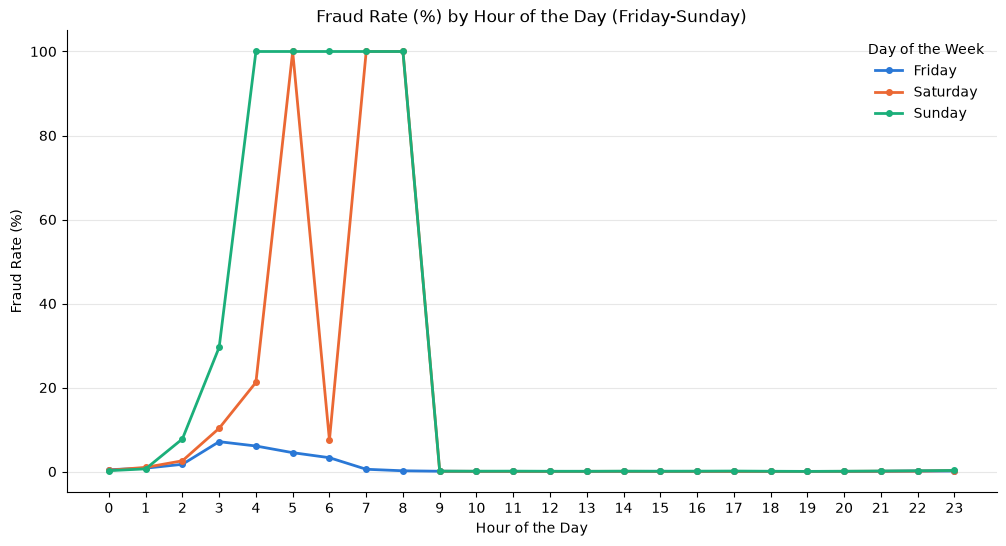

In [66]:
# Single chart showing the fraud rate (%) by hour of the day for Friday, Saturday and Sunday
weekend_days = ['Friday', 'Saturday', 'Sunday']
weekend_colors = ['#2a78d6', '#eb6834', '#1baf7a']

# Fraud rate per (day_of_week, hour_of_day) = fraudulent transactions / all transactions * 100
fraud_rate_by_weekend_hour = (df[df['day_of_week'].isin(weekend_days)]
                              .groupby(['day_of_week', 'hour_of_day'])['isFraud'].mean()
                              .mul(100)
                              .unstack('day_of_week')
                              .reindex(index=range(24), columns=weekend_days))

fig, ax = plt.subplots(figsize=(12, 6))
for day, color in zip(weekend_days, weekend_colors):
    ax.plot(fraud_rate_by_weekend_hour.index, fraud_rate_by_weekend_hour[day], label=day, color=color, linewidth=2, marker='o', markersize=4)

ax.set_title('Fraud Rate (%) by Hour of the Day (Friday-Sunday)')
ax.set_xlabel('Hour of the Day')
ax.set_ylabel('Fraud Rate (%)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(title='Day of the Week', frameon=False)
plt.show()

In [ ]:
# drop 'day_od_week' and 'errorOrig' columns from the dataframe
df = df.drop(columns=['day_of_week', 'errorOrig'])

KeyError: "['day_of_week'] not found in axis"

In [73]:
df.head(10)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour_of_day,day
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0,1,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0,1,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0,1,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0,1,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0,1,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0,1,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0,1,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0,1,0


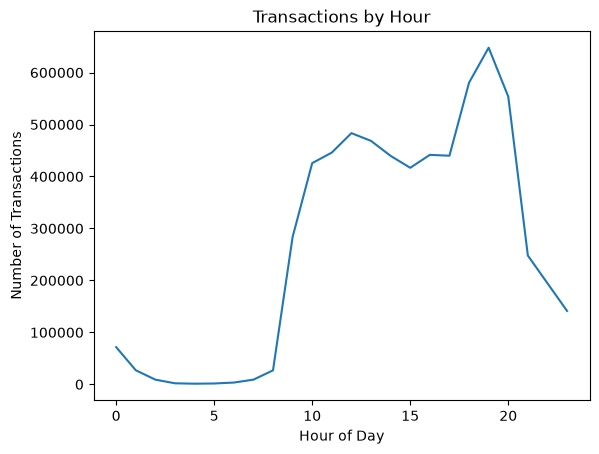

In [75]:
# line chart showing the total number of transactions by hour of day
transactions_by_hour = df.groupby('hour_of_day')['isFraud'].count()
plt.plot(transactions_by_hour.index, transactions_by_hour.values)
plt.xlabel('Hour of Day')
plt.ylabel('Number of Transactions')
plt.title('Transactions by Hour')
plt.show()

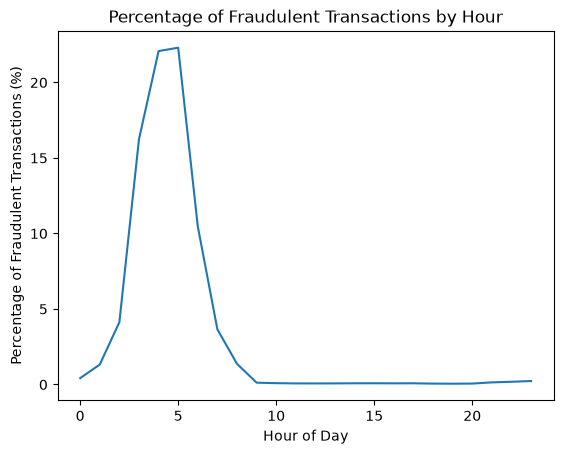

In [76]:
# line chart showing percentage of transaction at each hour which are fraudulent
fraudulent_transactions_by_hour = df[df['isFraud'] == 1].groupby('hour_of_day')['isFraud'].count()
percentage_fraudulent_transactions_by_hour = (fraudulent_transactions_by_hour / transactions_by_hour) * 100
plt.plot(percentage_fraudulent_transactions_by_hour.index, percentage_fraudulent_transactions_by_hour.values)
plt.xlabel('Hour of Day')
plt.ylabel('Percentage of Fraudulent Transactions (%)')
plt.title('Percentage of Fraudulent Transactions by Hour')
plt.show()

In [77]:
# describe the 'amount' column in the dataframe
amount_description = df['amount'].describe()
print(amount_description)

count    6.362620e+06
mean     1.798619e+05
std      6.038582e+05
min      0.000000e+00
25%      1.338957e+04
50%      7.487194e+04
75%      2.087215e+05
max      9.244552e+07
Name: amount, dtype: float64


           transactions  fraud_rate_%
amount                               
<1K              142646         0.041
1K-10K          1143445         0.019
10K-50K         1519856         0.050
50K-100K         719351         0.093
100K-200K       1163752         0.089
200K-500K       1333286         0.121
500K-1M          209658         0.552
1M-10M           128183         2.111
>10M               2443         0.000


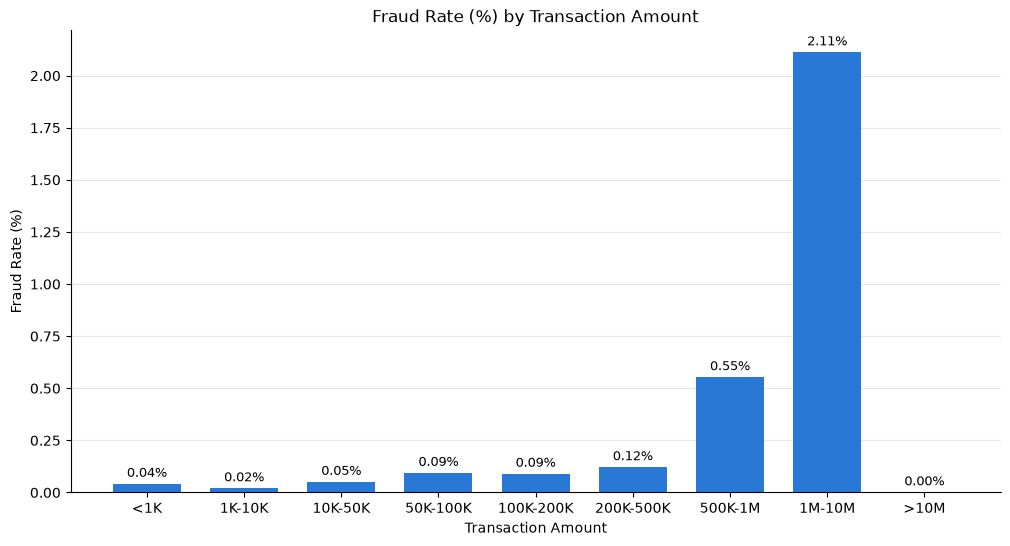

In [78]:
# Bar chart showing the fraud rate (%) within each transaction amount bucket
amount_bins = [0, 1_000, 10_000, 50_000, 100_000, 200_000, 500_000, 1_000_000, 10_000_000, np.inf]
amount_labels = ['<1K', '1K-10K', '10K-50K', '50K-100K', '100K-200K', '200K-500K', '500K-1M', '1M-10M', '>10M']

amount_bucket = pd.cut(df['amount'], bins=amount_bins, labels=amount_labels, include_lowest=True)

# Fraud rate per bucket = fraudulent transactions / all transactions in the bucket * 100
fraud_rate_by_amount = df.groupby(amount_bucket, observed=False)['isFraud'].mean().mul(100)
transactions_by_amount = amount_bucket.value_counts().reindex(amount_labels)
print(pd.DataFrame({'transactions': transactions_by_amount, 'fraud_rate_%': fraud_rate_by_amount.round(3)}))

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(fraud_rate_by_amount.index.astype(str), fraud_rate_by_amount.values, color='#2a78d6', width=0.7)
ax.bar_label(bars, fmt='%.2f%%', padding=3, fontsize=9)

ax.set_title('Fraud Rate (%) by Transaction Amount')
ax.set_xlabel('Transaction Amount')
ax.set_ylabel('Fraud Rate (%)')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

In [79]:
df.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour_of_day,day
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0,1,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0,1,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0,1,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0,1,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0,1,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0,1,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0,1,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0,1,0


In [80]:
# Recipient (nameDest) behaviour features. Each row only uses the recipient's earlier transactions,
# so nothing from the current or future transactions leaks into the features.
# Rows are ordered by step, and rows within the same step keep their original file order.
dest_sorted = df.sort_values(['nameDest', 'step'], kind='stable')
dest_groups = dest_sorted.groupby('nameDest', sort=False)

# Number of transactions the recipient received before this one
df['dest_prev_txn_count'] = dest_groups.cumcount()

# Total amount the recipient received before this one
df['dest_prev_amount_sum'] = dest_groups['amount'].cumsum() - dest_sorted['amount']

# 1 if this is the first time the recipient receives money, otherwise 0
df['dest_is_first_txn'] = (df['dest_prev_txn_count'] == 0).astype(int)

# Number of transactions the recipient received in the past 24 steps (the current step and the 23 before it),
# not counting this one. Rows are sorted by (recipient, step), so searchsorted finds where each window starts.
dest_codes = dest_sorted['nameDest'].factorize()[0].astype(np.int64)
dest_steps = dest_sorted['step'].to_numpy(dtype=np.int64)
sort_key = dest_codes * 1_000 + dest_steps
window_start = np.searchsorted(sort_key, sort_key - 23, side='left')
df['dest_txn_count_24h'] = pd.Series(np.arange(len(dest_sorted)) - window_start, index=dest_sorted.index)

df.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour_of_day,day,dest_prev_txn_count,dest_prev_amount_sum,dest_is_first_txn,dest_txn_count_24h
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0,1,0,0,0.0,1,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0,1,0,0,0.0,1,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0,1,0,0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0,1,0,0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0,1,0,0,0.0,1,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0,1,0,0,0.0,1,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0,1,0,0,0.0,1,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0,1,0,0,0.0,1,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0,1,0,0,0.0,1,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0,1,0,0,0.0,1,0


In [ ]:
# Bar chart showing the fraud rate (%) by how much money the recipient had already received (dest_prev_amount_sum)
prev_amount_bins = [-np.inf, 0, 100_000, 1_000_000, 5_000_000, 10_000_000, np.inf]
prev_amount_labels = ['None before', '<100K', '100K-1M', '1M-5M', '5M-10M', '>10M']

prev_amount_bucket = pd.cut(df['dest_prev_amount_sum'], bins=prev_amount_bins, labels=prev_amount_labels)

# Fraud rate per bucket = fraudulent transactions / all transactions in the bucket * 100
fraud_rate_by_prev_amount = df.groupby(prev_amount_bucket, observed=False)['isFraud'].mean().mul(100)
transactions_by_prev_amount = prev_amount_bucket.value_counts().reindex(prev_amount_labels)
print(pd.DataFrame({'transactions': transactions_by_prev_amount, 'fraud_rate_%': fraud_rate_by_prev_amount.round(3)}))

overall_fraud_rate = df['isFraud'].mean() * 100

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(fraud_rate_by_prev_amount.index.astype(str), fraud_rate_by_prev_amount.values, color='#2a78d6', width=0.7)
ax.bar_label(bars, fmt='%.3f%%', padding=3, fontsize=9)

# Dashed reference line at the overall fraud rate
ax.axhline(overall_fraud_rate, color='#6b6b6b', linestyle='--', linewidth=1)
ax.text(len(prev_amount_labels) - 0.5, overall_fraud_rate, f'Overall {overall_fraud_rate:.3f}%',
        ha='right', va='bottom', fontsize=9, color='#6b6b6b')

ax.set_title('Fraud Rate (%) by Amount the Recipient Received Before')
ax.set_xlabel('Amount Received by nameDest Before This Transaction')
ax.set_ylabel('Fraud Rate (%)')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

In [81]:
# A bar chart showing percentage of fraudulent transaction for each ctegory in dest_txn_count_24h
fraud_rate_by_dest_txn_count_24h = df.groupby('dest_txn_count_24h', observed=False)['isFraud'].mean().mul(100)
transactions_by_dest_txn_count_24h = df['dest_txn_count_24h'].value_counts().reindex(fraud_rate_by_dest_txn_count_24h.index)
print(pd.DataFrame({'transactions': transactions_by_dest_txn_count_24h, 'fraud_rate_%': fraud_rate_by_dest_txn_count_24h.round(3)}))

                    transactions  fraud_rate_%
dest_txn_count_24h                            
0                        3992125         0.180
1                        1077498         0.049
2                         544150         0.041
3                         261914         0.039
4                         134811         0.042
...                          ...           ...
88                             1         0.000
89                             1         0.000
90                             1         0.000
91                             1         0.000
92                             1         0.000

[93 rows x 2 columns]


In [82]:
# A bar chart showing percentage of fraudulent transaction for each ctegory in dest_txn_count
fraud_rate_by_dest_txn_count = df.groupby('dest_prev_txn_count', observed=False)['isFraud'].mean().mul(100)
transactions_by_dest_txn_count = df['dest_prev_txn_count'].value_counts().reindex(fraud_rate_by_dest_txn_count.index)
print(pd.DataFrame({'transactions': transactions_by_dest_txn_count, 'fraud_rate_%': fraud_rate_by_dest_txn_count.round(3)}))

                     transactions  fraud_rate_%
dest_prev_txn_count                            
0                         2722362         0.190
1                          459658         0.125
2                          382604         0.104
3                          325315         0.099
4                          280200         0.093
...                           ...           ...
108                             2         0.000
109                             1         0.000
110                             1         0.000
111                             1         0.000
112                             1         0.000

[113 rows x 2 columns]


# Final EDA

In [83]:
df.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour_of_day,day,dest_prev_txn_count,dest_prev_amount_sum,dest_is_first_txn,dest_txn_count_24h
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0,1,0,0,0.0,1,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0,1,0,0,0.0,1,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0,1,0,0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0,1,0,0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0,1,0,0,0.0,1,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0,1,0,0,0.0,1,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0,1,0,0,0.0,1,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0,1,0,0,0.0,1,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0,1,0,0,0.0,1,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0,1,0,0,0.0,1,0


                      transactions  fraud_rate_%
dest_prev_amount_sum                            
None before                2722364         0.190
<100K                       186396         0.151
100K-1M                    1399931         0.102
1M-5M                      1598895         0.067
5M-10M                      343762         0.054
>10M                        111272         0.073


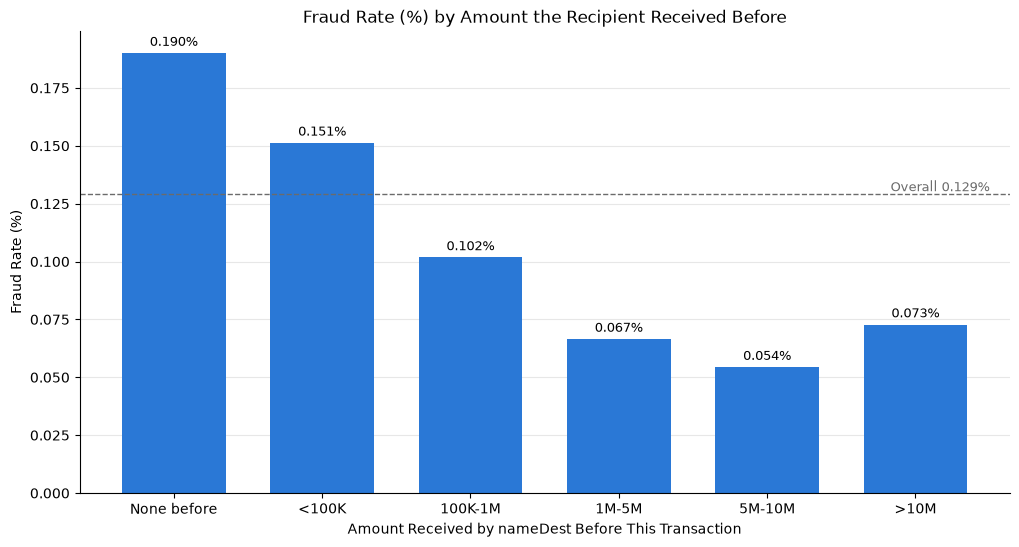

In [84]:
# Bar chart showing the fraud rate (%) by how much money the recipient had already received (dest_prev_amount_sum)
prev_amount_bins = [-np.inf, 0, 100_000, 1_000_000, 5_000_000, 10_000_000, np.inf]
prev_amount_labels = ['None before', '<100K', '100K-1M', '1M-5M', '5M-10M', '>10M']

prev_amount_bucket = pd.cut(df['dest_prev_amount_sum'], bins=prev_amount_bins, labels=prev_amount_labels)

# Fraud rate per bucket = fraudulent transactions / all transactions in the bucket * 100
fraud_rate_by_prev_amount = df.groupby(prev_amount_bucket, observed=False)['isFraud'].mean().mul(100)
transactions_by_prev_amount = prev_amount_bucket.value_counts().reindex(prev_amount_labels)
print(pd.DataFrame({'transactions': transactions_by_prev_amount, 'fraud_rate_%': fraud_rate_by_prev_amount.round(3)}))

overall_fraud_rate = df['isFraud'].mean() * 100

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(fraud_rate_by_prev_amount.index.astype(str), fraud_rate_by_prev_amount.values, color='#2a78d6', width=0.7)
ax.bar_label(bars, fmt='%.3f%%', padding=3, fontsize=9)

# Dashed reference line at the overall fraud rate
ax.axhline(overall_fraud_rate, color='#6b6b6b', linestyle='--', linewidth=1)
ax.text(len(prev_amount_labels) - 0.5, overall_fraud_rate, f'Overall {overall_fraud_rate:.3f}%',
        ha='right', va='bottom', fontsize=9, color='#6b6b6b')

ax.set_title('Fraud Rate (%) by Amount the Recipient Received Before')
ax.set_xlabel('Amount Received by nameDest Before This Transaction')
ax.set_ylabel('Fraud Rate (%)')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

In [85]:
# export df to a new CSV file called "Modelling.csv" in the Data directory
df.to_csv('../Data/Modelling.csv', index=False)